Instacart Market Basket Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


In [2]:
# Update this folder path to the folder containing the five CSV files.
data_dir = r"C:/Users/HP/Downloads/instamart"

instamart = pd.read_csv(os.path.join(data_dir, "order_products__prior.csv"))
orders = pd.read_csv(os.path.join(data_dir, "orders.csv"))
products = pd.read_csv(os.path.join(data_dir, "products.csv"))
aisles = pd.read_csv(os.path.join(data_dir, "aisles.csv"))
departments = pd.read_csv(os.path.join(data_dir, "departments.csv"))

print("All five Instacart tables loaded successfully.")
print("Rows:", {
    "orders": len(orders),
    "order_products__prior": len(instamart),
    "products": len(products),
    "aisles": len(aisles),
    "departments": len(departments)
})

All five Instacart tables loaded successfully.
Rows: {'orders': 3421083, 'order_products__prior': 32434489, 'products': 49688, 'aisles': 134, 'departments': 21}


# Data Quality Checks and Data Type Review

The source data is already clean, so this notebook does not create backup copies or automatically remove records. It includes validation checks, appropriate data type conversions, and visualizations.

## Data Type Changes

The conversions below are appropriate for the standard Instacart tables:
- Identifier and count columns use compact integer types where possible.
- `eval_set` and `reordered` use categorical types.
- `days_since_prior_order` remains numeric and keeps its missing values (first orders commonly have no prior-order gap).
- `order_dow` stays numeric for calculations; the readable day name is added separately.

In [3]:
# Orders
orders['order_id'] = orders['order_id'].astype('int32')
orders['user_id'] = orders['user_id'].astype('int32')
orders['order_number'] = orders['order_number'].astype('int16')
orders['order_dow'] = orders['order_dow'].astype('int8')
orders['order_hour_of_day'] = orders['order_hour_of_day'].astype('int8')
orders['days_since_prior_order'] = orders['days_since_prior_order'].astype('float32')

# Order products
instamart['order_id'] = instamart['order_id'].astype('int32')
instamart['product_id'] = instamart['product_id'].astype('int32')
instamart['add_to_cart_order'] = instamart['add_to_cart_order'].astype('int16')
instamart['reordered'] = instamart['reordered'].astype('int8')

# Products
products['product_id'] = products['product_id'].astype('int32')
products['aisle_id'] = products['aisle_id'].astype('int16')
products['department_id'] = products['department_id'].astype('int8')

# Aisles and departments
aisles['aisle_id'] = aisles['aisle_id'].astype('int16')
departments['department_id'] = departments['department_id'].astype('int8')

# Check data types
print("Orders data types:")
print(orders.dtypes)

print("\\nOrder products data types:")
print(instamart.dtypes)

print("\\nProducts data types:")
print(products.dtypes)

print("\\nAisles data types:")
print(aisles.dtypes)

print("\\nDepartments data types:")
print(departments.dtypes)

Orders data types:
order_id                    int32
user_id                     int32
eval_set                      str
order_number                int16
order_dow                    int8
order_hour_of_day            int8
days_since_prior_order    float32
dtype: object
\nOrder products data types:
order_id             int32
product_id           int32
add_to_cart_order    int16
reordered             int8
dtype: object
\nProducts data types:
product_id       int32
product_name       str
aisle_id         int16
department_id     int8
dtype: object
\nAisles data types:
aisle_id    int16
aisle         str
dtype: object
\nDepartments data types:
department_id    int8
department        str
dtype: object


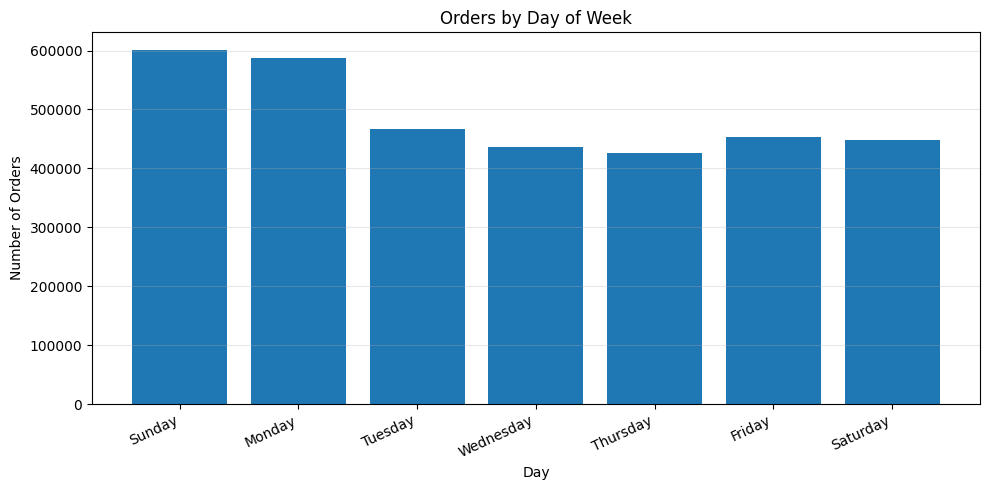

In [4]:
# Graph 4: Orders by day of week (Instacart encoding: 0=Sunday ... 6=Saturday)
day_labels = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
orders_by_day_check = orders.groupby("order_dow")["order_id"].nunique().reindex(range(7), fill_value=0)

plt.figure(figsize=(10, 5))
plt.bar(day_labels, orders_by_day_check.values)
plt.title("Orders by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Orders")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

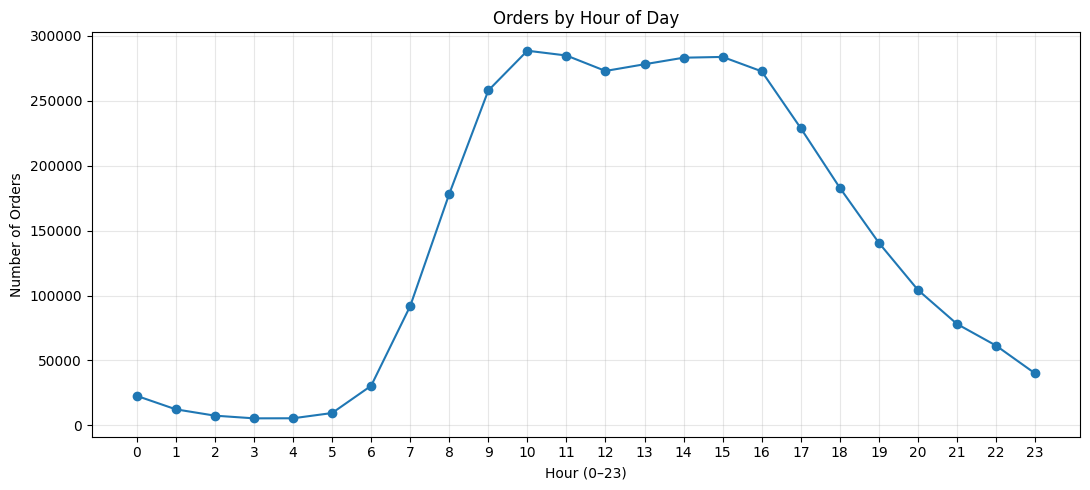

In [5]:
# Graph 5: Orders by hour
orders_by_hour_check = orders.groupby("order_hour_of_day")["order_id"].nunique().reindex(range(24), fill_value=0)

plt.figure(figsize=(11, 5))
plt.plot(orders_by_hour_check.index, orders_by_hour_check.values, marker="o")
plt.title("Orders by Hour of Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Number of Orders")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

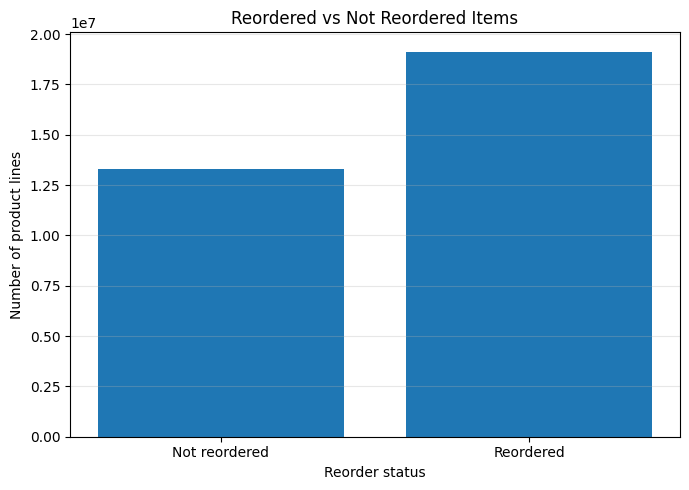

In [6]:
# Graph 6: Reordered vs first-time product lines
reorder_counts = instamart["reordered"].value_counts().reindex([0, 1], fill_value=0)

plt.figure(figsize=(7, 5))
plt.bar(["Not reordered", "Reordered"], reorder_counts.values)
plt.title("Reordered vs Not Reordered Items")
plt.xlabel("Reorder status")
plt.ylabel("Number of product lines")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

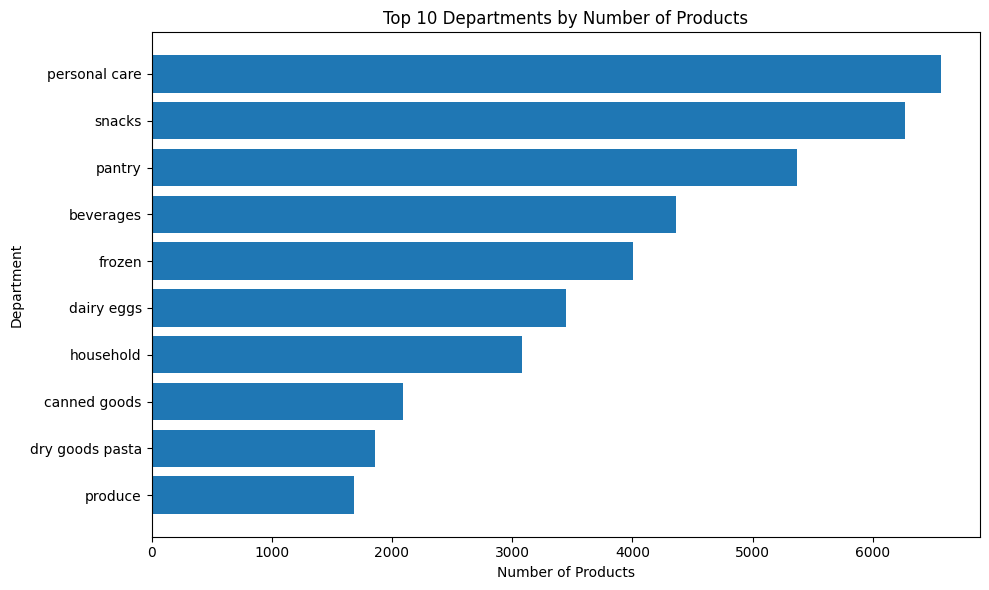

In [7]:
# Graph 7: Top 10 departments by number of products
products_by_department = (
    products.merge(departments, on="department_id", how="left")
    .groupby("department", dropna=False)["product_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
plt.barh(products_by_department.index.astype(str)[::-1], products_by_department.values[::-1])
plt.title("Top 10 Departments by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

In [8]:
instamart.head()

,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


In [9]:
#Compare reorder rates between morning orders and evening orders.
merge=instamart.merge(orders,on='order_id')

def time_period(hour):
    if hour <12:
        return 'Morning'
    elif hour >=18:
        return 'Evening'
    return 'other'

merge['time_period']=merge['order_hour_of_day'].apply(time_period)
merge[merge['time_period'].isin(['Morning','Evening'])].groupby('time_period')['reordered'].mean()*100

time_period
Evening    57.928157
Morning    60.876496
Name: reordered, dtype: float64

In [10]:
# What is the most popular product ordered on Saturdays specifically?
merged = instamart.merge(orders, on='order_id').merge(products, on='product_id')
saturday_orders = merged[merged['order_dow'] == 6]  # Instacart: 6 = Saturday
saturday_orders['product_name'].value_counts().idxmax()

'Banana'

In [11]:
orders.head()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


In [12]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int32  
 1   user_id                 int32  
 2   eval_set                str    
 3   order_number            int16  
 4   order_dow               int8   
 5   order_hour_of_day       int8   
 6   days_since_prior_order  float32
dtypes: float32(1), int16(1), int32(2), int8(2), str(1)
memory usage: 78.3 MB


In [13]:
user_order_count=orders['user_id'].value_counts()


In [14]:
# how many user order place most and how many user 
max_orders=user_order_count.max()
max_orders
num_user_with_max=(user_order_count==max_orders).sum()
num_user_with_max

np.int64(1374)

In [15]:
#what percentage of orders happen on weekend
weekend_order=orders[orders['order_dow'].isin([0,6])].shape[0]
percentage=(weekend_order/orders.shape[0])*100
percentage

30.682272251214016

In [16]:
#What is the most common order_hour_of_day? 
orders['order_hour_of_day'].value_counts().idxmax()

np.int8(10)

In [17]:
#  How many orders have order_number = 1 (first-time orders)?
(orders['order_number']==1).sum()


np.int64(206209)

In [18]:
#What is the busiest hour on Saturdays specifically?
saturday_order=orders.query('order_dow == 6')
saturday_order['order_hour_of_day'].value_counts().idxmax()

np.int8(14)

In [19]:
departments.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   department_id  21 non-null     int8 
 1   department     21 non-null     str  
dtypes: int8(1), str(1)
memory usage: 321.0 bytes


In [20]:
departments.duplicated().sum()

np.int64(0)

aisles

In [21]:
aisles.head()

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


In [22]:
aisles.info()

<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   aisle_id  134 non-null    int16
 1   aisle     134 non-null    str  
dtypes: int16(1), str(1)
memory usage: 1.4 KB


In [23]:
aisles.isnull().sum()

aisle_id    0
aisle       0
dtype: int64

In [24]:
aisles.duplicated().sum()

np.int64(0)

merge table (order_details)

In [25]:
check_order=pd.merge(orders,instamart,on='order_id',how='inner')
check_order

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered
0,2539329,1,prior,1,2,8,NaN,196,1,0
1,2539329,1,prior,1,2,8,NaN,14084,2,0
2,2539329,1,prior,1,2,8,NaN,12427,3,0
3,2539329,1,prior,1,2,8,NaN,26088,4,0
4,2539329,1,prior,1,2,8,NaN,26405,5,0
...,...,...,...,...,...,...,...,...,...,...
32434484,2977660,206209,prior,13,1,12,7.0,14197,5,1
32434485,2977660,206209,prior,13,1,12,7.0,38730,6,0
32434486,2977660,206209,prior,13,1,12,7.0,31477,7,0
32434487,2977660,206209,prior,13,1,12,7.0,6567,8,0


In [26]:
order_details=pd.merge(check_order,products,on='product_id')
order_details

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id
0,2539329,1,prior,1,2,8,NaN,196,1,0,Soda,77,7
1,2539329,1,prior,1,2,8,NaN,14084,2,0,Organic Unsweetened Vanilla Almond Milk,91,16
2,2539329,1,prior,1,2,8,NaN,12427,3,0,Original Beef Jerky,23,19
3,2539329,1,prior,1,2,8,NaN,26088,4,0,Aged White Cheddar Popcorn,23,19
4,2539329,1,prior,1,2,8,NaN,26405,5,0,XL Pick-A-Size Paper Towel Rolls,54,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32434484,2977660,206209,prior,13,1,12,7.0,14197,5,1,Tomato Paste,9,9
32434485,2977660,206209,prior,13,1,12,7.0,38730,6,0,Brownie Crunch High Protein Bar,3,19
32434486,2977660,206209,prior,13,1,12,7.0,31477,7,0,High Protein Bar Chunky Peanut Butter,3,19
32434487,2977660,206209,prior,13,1,12,7.0,6567,8,0,Chocolate Peanut Butter Protein Bar,3,19


apriori

In [27]:
#products_per_order=order_details.groupby('order_id')['product_id'].count().reset_index(name='total_products')#get product count per order 
#products_per_order

In [28]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int32  
 1   user_id                 int32  
 2   eval_set                str    
 3   order_number            int16  
 4   order_dow               int8   
 5   order_hour_of_day       int8   
 6   days_since_prior_order  float32
dtypes: float32(1), int16(1), int32(2), int8(2), str(1)
memory usage: 78.3 MB


In [29]:
products.head()

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [30]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 49688 entries, 0 to 49687
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   product_id     49688 non-null  int32
 1   product_name   49688 non-null  str  
 2   aisle_id       49688 non-null  int16
 3   department_id  49688 non-null  int8 
dtypes: int16(1), int32(1), int8(1), str(1)
memory usage: 728.0 KB


In [31]:
products.isnull().sum()

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

In [32]:
instamart.tail()

,order_id,product_id,add_to_cart_order,reordered
32434484,3421083,39678,6,1
32434485,3421083,11352,7,0
32434486,3421083,4600,8,0
32434487,3421083,24852,9,1
32434488,3421083,5020,10,1


In [33]:
instamart.info()

<class 'pandas.DataFrame'>
RangeIndex: 32434489 entries, 0 to 32434488
Data columns (total 4 columns):
 #   Column             Dtype
---  ------             -----
 0   order_id           int32
 1   product_id         int32
 2   add_to_cart_order  int16
 3   reordered          int8 
dtypes: int16(1), int32(2), int8(1)
memory usage: 340.3 MB


In [34]:
instamart.groupby('reordered')['order_id'].count()

reordered
0    13307953
1    19126536
Name: order_id, dtype: int64

In [35]:
instamart.isnull().sum()

order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

In [36]:
aisles.info()
aisles['aisle_id']=aisles['aisle_id'].astype(int)

<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   aisle_id  134 non-null    int16
 1   aisle     134 non-null    str  
dtypes: int16(1), str(1)
memory usage: 1.4 KB


In [37]:
products_full=products.merge(aisles,on='aisle_id').merge(departments,on='department_id')
products_full

,product_id,product_name,aisle_id,department_id,aisle,department
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks
1,2,All-Seasons Salt,104,13,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1,frozen meals,frozen
4,5,Green Chile Anytime Sauce,5,13,marinades meat preparation,pantry
...,...,...,...,...,...,...
49683,49684,"Vodka, Triple Distilled, Twist of Vanilla",124,5,spirits,alcohol
49684,49685,En Croute Roast Hazelnut Cranberry,42,1,frozen vegan vegetarian,frozen
49685,49686,Artisan Baguette,112,3,bread,bakery
49686,49687,Smartblend Healthy Metabolism Dry Cat Food,41,8,cat food care,pets


In [38]:
orders.groupby('order_dow')['order_id'].nunique().sort_values(ascending=False)# find which dow is place order high 

order_dow
0    600905
1    587478
2    467260
5    453368
6    448761
3    436972
4    426339
Name: order_id, dtype: int64

In [39]:
orders.groupby('order_hour_of_day')['order_id'].count().sort_values(ascending=False)#order place by order_hour_of_day

order_hour_of_day
10    288418
11    284728
15    283639
14    283042
13    277999
12    272841
16    272553
9     257812
17    228795
18    182912
8     178201
19    140569
20    104292
7      91868
21     78109
22     61468
23     40043
6      30529
0      22758
1      12398
5       9569
2       7539
4       5527
3       5474
Name: order_id, dtype: int64

In [40]:
first_five_depart=departments['department']

for dept in first_five_depart:
    count=products_full[products_full['department']==dept].shape[0]
    print (f"{dept}:{count} products")

frozen:4007 products
other:548 products
bakery:1516 products
produce:1684 products
alcohol:1054 products
international:1139 products
beverages:4365 products
pets:972 products
dry goods pasta:1858 products
bulk:38 products
personal care:6563 products
meat seafood:907 products
pantry:5371 products
breakfast:1115 products
canned goods:2092 products
dairy eggs:3449 products
household:3085 products
babies:1081 products
snacks:6264 products
deli:1322 products
missing:1258 products


In [41]:
full_data = (
    instamart
    .merge(orders, on='order_id', how='inner')
    .merge(products_full, on='product_id', how='inner')
)

# Check the result
print(full_data.shape)   # expected: (32434489, 13)
print(full_data.columns.tolist())
full_data.head()

(32434489, 15)
['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_name', 'aisle_id', 'department_id', 'aisle', 'department']


,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients,pantry


In [42]:
user_total=orders.groupby('user_id')['order_id'].nunique()
full_data['total_orders']=full_data['user_id'].map(user_total).astype('int16')

In [43]:
full_data.head()

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department,total_orders
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs,9
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce,9
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry,9
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry,9
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients,pantry,9


## Day-of-Week Encoding and Visualizations

In the Instacart `orders` dataset, `order_dow` uses this convention:
- `0` = Sunday
- `1` = Monday
- `2` = Tuesday
- `3` = Wednesday
- `4` = Thursday
- `5` = Friday
- `6` = Saturday

We will create readable day names, an ordered categorical column, and one-hot encoded columns. The plots use the smaller `orders` table rather than the much larger product-level `full_data` table.

In [44]:
# 1. Convert numeric day values into day names
day_map = {
    0: 'Sunday',
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday'
}

day_order = ['Sunday', 'Monday', 'Tuesday', 'Wednesday',
             'Thursday', 'Friday', 'Saturday']

orders['day_of_week'] = orders['order_dow'].map(day_map)

# Keep the days in calendar order (not alphabetical order)
orders['day_of_week'] = pd.Categorical(
    orders['day_of_week'],
    categories=day_order,
    ordered=True
)

orders[['order_dow', 'day_of_week']].head()

,order_dow,day_of_week
0,2,Tuesday
1,3,Wednesday
2,3,Wednesday
3,4,Thursday
4,4,Thursday


In [45]:
# 2. One-hot encode the day-of-week column
day_encoding = pd.get_dummies(
    orders['day_of_week'],
    prefix='day',
    dtype=int
)

# Add the encoded columns to the orders dataframe
orders = pd.concat([orders, day_encoding], axis=1)

orders[['day_of_week'] + day_encoding.columns.tolist()].head()

,day_of_week,day_Sunday,day_Monday,day_Tuesday,day_Wednesday,day_Thursday,day_Friday,day_Saturday
0,Tuesday,0,0,1,0,0,0,0
1,Wednesday,0,0,0,1,0,0,0
2,Wednesday,0,0,0,1,0,0,0
3,Thursday,0,0,0,0,1,0,0
4,Thursday,0,0,0,0,1,0,0


### Plot 1: Number of orders by day of the week

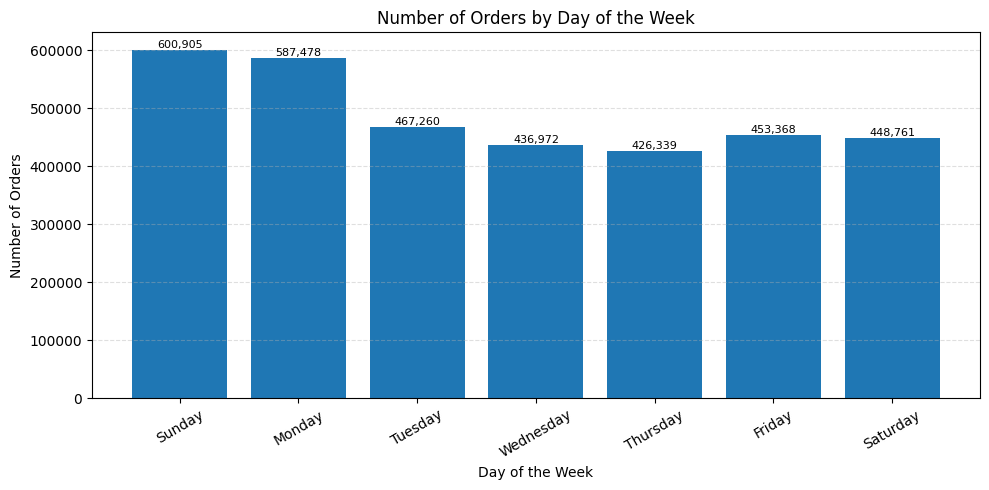

In [46]:
# Count unique orders for each day and retain calendar order
orders_by_day = (
    orders.groupby('day_of_week', observed=False)['order_id']
    .nunique()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))
bars = plt.bar(orders_by_day.index, orders_by_day.values)
plt.title('Number of Orders by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Orders')
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():,.0f}',
        ha='center',
        va='bottom',
        fontsize=8
    )

plt.tight_layout()
plt.show()

### Plot 2: Number of orders by hour of the day

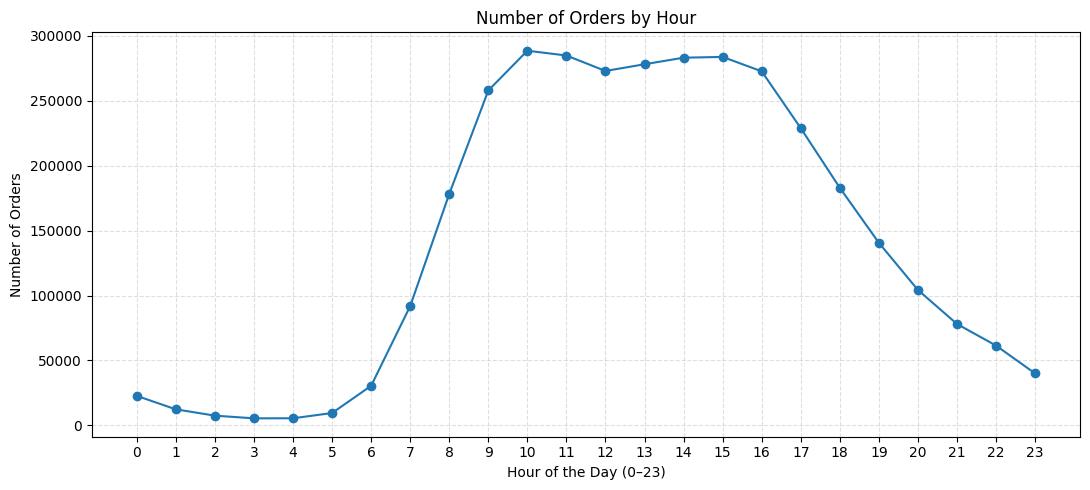

In [47]:
orders_by_hour = (
    orders.groupby('order_hour_of_day')['order_id']
    .nunique()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(11, 5))
plt.plot(orders_by_hour.index, orders_by_hour.values, marker='o')
plt.title('Number of Orders by Hour')
plt.xlabel('Hour of the Day (0–23)')
plt.ylabel('Number of Orders')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Plot 3: Orders by day and hour (heatmap)

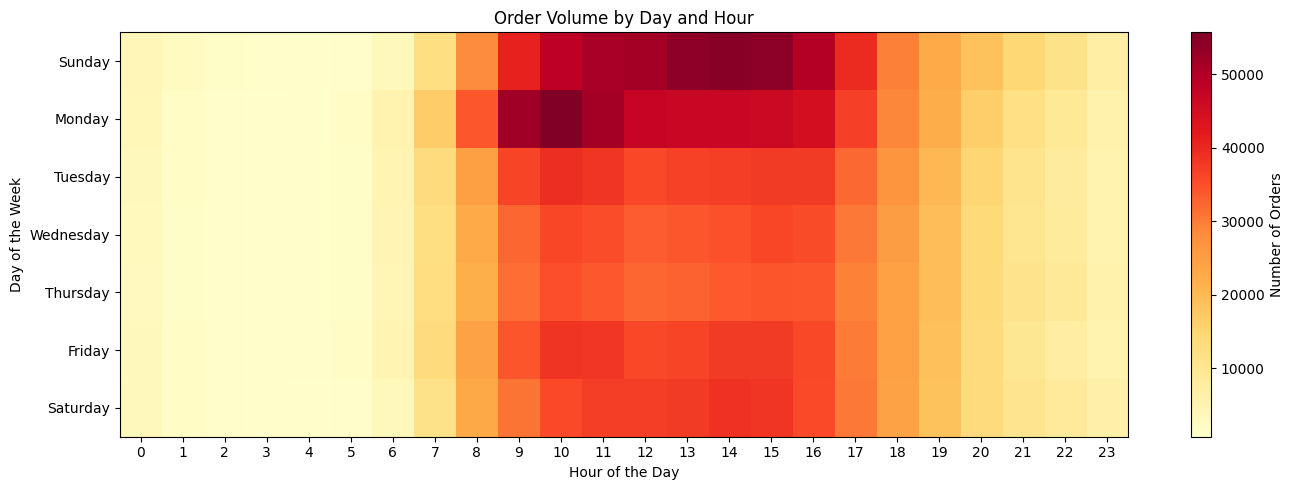

In [48]:
orders_day_hour = pd.crosstab(
    orders['day_of_week'],
    orders['order_hour_of_day']
).reindex(day_order)

plt.figure(figsize=(14, 5))
plt.imshow(orders_day_hour, aspect='auto', cmap='YlOrRd')
plt.title('Order Volume by Day and Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Day of the Week')
plt.xticks(range(24), range(24))
plt.yticks(range(len(day_order)), day_order)
plt.colorbar(label='Number of Orders')
plt.tight_layout()
plt.show()

### Interpretation

- Plot 1 helps identify the busiest day of the week.
- Plot 2 shows the peak ordering hours.
- Plot 3 combines both dimensions to show which day-and-hour combinations have the highest order volume.

Use the charts' actual results to write your business observations; do not assume a busiest day or hour before checking the plots.